# ConnectX Churn Prediction: Preprocessing and Model Training

This section loads the dataset, cleans missing values, encodes categorical variables, and performs an 80/20 stratified train/test split.

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Load the selected dataset
file_path = '/content/telecom_churn (1).csv'
df = pd.read_csv(file_path)

print("Columns in dataset:", df.columns.tolist())

# Separate features and target
target_col = 'churn'

# Drop high cardinality/uninformative identifier column 'phone number'
X = df.drop(columns=[target_col, 'phone number'])
y = df[target_col]

# Ensure target is boolean or numeric for training
if y.dtype == 'object':
    y = y.map({'TRUE': True, 'FALSE': False, True: True, False: False})

# Identify numeric and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print(f"\nNumerical Columns: {num_cols}")
print(f"Categorical Columns: {cat_cols}")

# Preprocessing pipeline
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Partition into 80% training and 20% testing (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Columns in dataset: ['state', 'account length', 'area code', 'phone number', 'international plan', 'voice mail plan', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls', 'churn']

Numerical Columns: ['account length', 'area code', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls']
Categorical Columns: ['state', 'international plan', 'voice mail plan']

Training set shape: (2666, 19)
Testing set shape: (667, 19)


# Model Training and Evaluation

Here we train **Logistic Regression**, **Decision Tree**, and **Random Forest** models and compile their performance metrics into a comparison summary table.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Define the three models
model_a = LogisticRegression(max_iter=1000, random_state=42)
model_b = DecisionTreeClassifier(max_depth=5, random_state=42)
model_c = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

models = {
    'Logistic Regression': model_a,
    'Decision Tree': model_b,
    'Random Forest': model_c
}

results = {}

for name, model in models.items():
    # Construct full pipeline with preprocessor and model
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }

# Create comparative summary table
summary_df = pd.DataFrame(results)
display(summary_df)

,Logistic Regression,Decision Tree,Random Forest
Accuracy,0.860570,0.914543,0.883058
Precision,0.543478,0.750000,0.913043
Recall,0.257732,0.618557,0.216495
F1 Score,0.349650,0.677966,0.350000


In [8]:
# Map boolean results to descriptive target labels ('churned' or 'retained')
target_mapping = {True: 'churned', False: 'retained'}

# Create a DataFrame comparing actuals and predictions for the best performing model (Decision Tree)
best_model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_b)
])

best_model_pipeline.fit(X_train, y_train)
test_predictions = best_model_pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual Churn Status': y_test.map(target_mapping),
    'Predicted Churn Status': pd.Series(test_predictions, index=y_test.index).map(target_mapping)
})

print("Sample Predictions showing True Churned vs Retained predictions:")
display(comparison_df.head(10))

Sample Predictions showing True Churned vs Retained predictions:


,Actual Churn Status,Predicted Churn Status
601,churned,churned
2050,retained,retained
3200,retained,retained
1953,retained,retained
1119,retained,retained
2204,retained,retained
1888,retained,retained
738,retained,retained
3087,retained,retained
539,retained,retained


=== Model A: Logistic Regression Performance Summary ===
              precision    recall  f1-score   support

    retained       0.88      0.96      0.92       570
     churned       0.54      0.26      0.35        97

    accuracy                           0.86       667
   macro avg       0.71      0.61      0.64       667
weighted avg       0.83      0.86      0.84       667



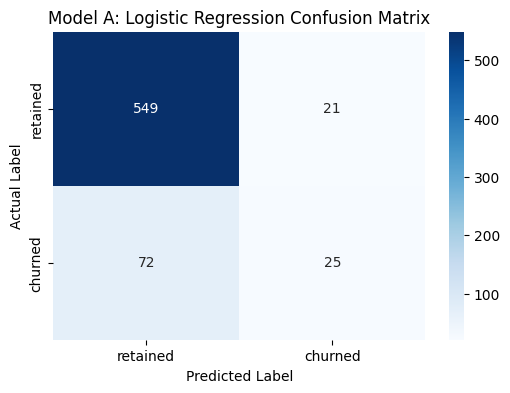

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Instantiate Model A (Logistic Regression)
model_a_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train Model A
model_a_pipeline.fit(X_train, y_train)

# Predict
y_pred_a = model_a_pipeline.predict(X_test)

# Output Classification Report
print("=== Model A: Logistic Regression Performance Summary ===")
print(classification_report(y_test, y_pred_a, target_names=['retained', 'churned']))

# Display Confusion Matrix
cm = confusion_matrix(y_test, y_pred_a)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['retained', 'churned'], yticklabels=['retained', 'churned'])
plt.title('Model A: Logistic Regression Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

=== Model B: Decision Tree Performance Summary ===
              precision    recall  f1-score   support

    retained       0.94      0.96      0.95       570
     churned       0.75      0.62      0.68        97

    accuracy                           0.91       667
   macro avg       0.84      0.79      0.81       667
weighted avg       0.91      0.91      0.91       667



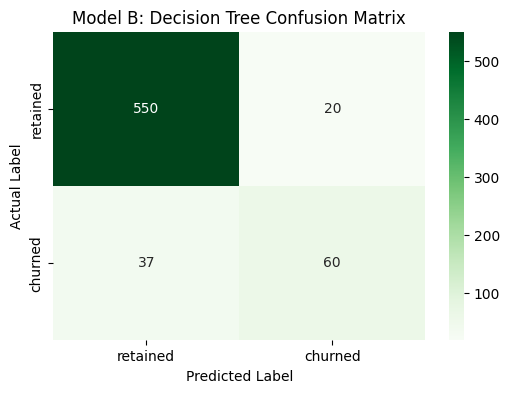

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Instantiate Model B (Decision Tree Classifier)
model_b_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))
])

# Train Model B
model_b_pipeline.fit(X_train, y_train)

# Predict
y_pred_b = model_b_pipeline.predict(X_test)

# Output Classification Report
print("=== Model B: Decision Tree Performance Summary ===")
print(classification_report(y_test, y_pred_b, target_names=['retained', 'churned']))

# Display Confusion Matrix
cm_b = confusion_matrix(y_test, y_pred_b)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_b, annot=True, fmt='d', cmap='Greens', xticklabels=['retained', 'churned'], yticklabels=['retained', 'churned'])
plt.title('Model B: Decision Tree Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

=== Model C: Random Forest Performance Summary ===
              precision    recall  f1-score   support

    retained       0.88      1.00      0.94       570
     churned       0.91      0.22      0.35        97

    accuracy                           0.88       667
   macro avg       0.90      0.61      0.64       667
weighted avg       0.89      0.88      0.85       667



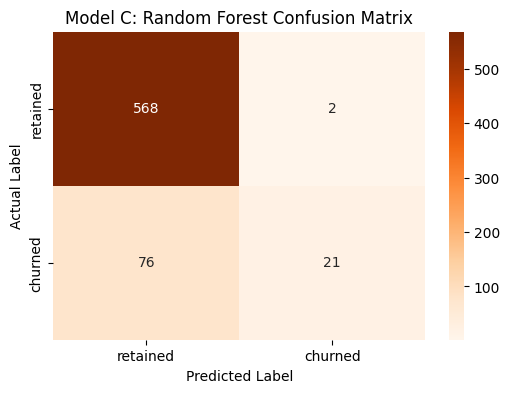

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Instantiate Model C (Random Forest Classifier)
model_c_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

# Train Model C
model_c_pipeline.fit(X_train, y_train)

# Predict
y_pred_c = model_c_pipeline.predict(X_test)

# Output Classification Report
print("=== Model C: Random Forest Performance Summary ===")
print(classification_report(y_test, y_pred_c, target_names=['retained', 'churned']))

# Display Confusion Matrix
cm_c = confusion_matrix(y_test, y_pred_c)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_c, annot=True, fmt='d', cmap='Oranges', xticklabels=['retained', 'churned'], yticklabels=['retained', 'churned'])
plt.title('Model C: Random Forest Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [16]:
from sklearn.ensemble import RandomForestClassifier

# Instantiate Model C with corrected parameters
model_c = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

print("Model C initialized successfully:", model_c)

Model C initialized successfully: RandomForestClassifier(max_depth=5, random_state=42)


In [17]:
import pandas as pd

# Define the full pipelines for each model using the existing fitted configurations
pipelines = {
    'Model A (Logistic Regression)': model_a_pipeline,
    'Model B (Decision Tree)': model_b_pipeline,
    'Model C (Random Forest)': model_c_pipeline
}

# Prepare an output DataFrame to hold the actuals and all model predictions
prediction_summary_df = pd.DataFrame({
    'Actual Class': y_test.map({True: 'TRUE', False: 'FALSE'})
}, index=y_test.index)

# Predict classes and probabilities for each model
for name, pipeline in pipelines.items():
    # Get boolean predictions
    preds_bool = pipeline.predict(X_test)
    # Map to TRUE/FALSE strings
    prediction_summary_df[f'{name} Prediction'] = pd.Series(preds_bool, index=y_test.index).map({True: 'TRUE', False: 'FALSE'})

    # Get prediction probabilities for the positive class (True/churned)
    probs = pipeline.predict_proba(X_test)[:, 1]
    prediction_summary_df[f'{name} Prob (Churn)'] = pd.Series(probs, index=y_test.index)

# Display sample outputs
print("=== Predictions and Probability Outputs Across All Three Models ===")
display(prediction_summary_df.head(10))

=== Predictions and Probability Outputs Across All Three Models ===


,Actual Class,Model A (Logistic Regression) Prediction,Model A (Logistic Regression) Prob (Churn),Model B (Decision Tree) Prediction,Model B (Decision Tree) Prob (Churn),Model C (Random Forest) Prediction,Model C (Random Forest) Prob (Churn)
601,TRUE,FALSE,0.179497,TRUE,1.000000,FALSE,0.439523
2050,FALSE,FALSE,0.127461,FALSE,0.024076,FALSE,0.080289
3200,FALSE,FALSE,0.110799,FALSE,0.036765,FALSE,0.210881
1953,FALSE,FALSE,0.133437,FALSE,0.024076,FALSE,0.095824
1119,FALSE,FALSE,0.355988,FALSE,0.024076,FALSE,0.087755
2204,FALSE,FALSE,0.054792,FALSE,0.024076,FALSE,0.081803
1888,FALSE,FALSE,0.283371,FALSE,0.024076,FALSE,0.095977
738,FALSE,FALSE,0.114140,FALSE,0.024076,FALSE,0.091980
3087,FALSE,FALSE,0.035062,FALSE,0.024076,FALSE,0.093600
539,FALSE,FALSE,0.105147,FALSE,0.024076,FALSE,0.084740


In [19]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Define the fitted pipelines to evaluate
pipelines = {
    'Model A (Logistic Regression)': model_a_pipeline,
    'Model B (Decision Tree)': model_b_pipeline,
    'Model C (Random Forest)': model_c_pipeline
}

# Dictionary to store recorded metrics
recorded_metrics = {}

# Compute metrics for each model
for name, pipeline in pipelines.items():
    # Generate predictions
    y_pred = pipeline.predict(X_test)

    # Calculate required metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)  # Sensitivity
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Record metrics
    recorded_metrics[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall (Sensitivity)': rec,
        'F1 Score': f1
    }

# Convert to DataFrame for comparison
metrics_df = pd.DataFrame(recorded_metrics).T
print("=== Recorded Model Evaluation Metrics ===")
display(metrics_df)

=== Recorded Model Evaluation Metrics ===


,Accuracy,Precision,Recall (Sensitivity),F1 Score
Model A (Logistic Regression),0.860570,0.543478,0.257732,0.349650
Model B (Decision Tree),0.914543,0.750000,0.618557,0.677966
Model C (Random Forest),0.883058,0.913043,0.216495,0.350000


In [20]:
import pandas as pd

# Format the pre-computed metrics_df into the requested layout
comparative_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Logistic Regression': [
        metrics_df.loc['Model A (Logistic Regression)', 'Accuracy'],
        metrics_df.loc['Model A (Logistic Regression)', 'Precision'],
        metrics_df.loc['Model A (Logistic Regression)', 'Recall (Sensitivity)'],
        metrics_df.loc['Model A (Logistic Regression)', 'F1 Score']
    ],
    'Decision Tree': [
        metrics_df.loc['Model B (Decision Tree)', 'Accuracy'],
        metrics_df.loc['Model B (Decision Tree)', 'Precision'],
        metrics_df.loc['Model B (Decision Tree)', 'Recall (Sensitivity)'],
        metrics_df.loc['Model B (Decision Tree)', 'F1 Score']
    ],
    'Random Forest': [
        metrics_df.loc['Model C (Random Forest)', 'Accuracy'],
        metrics_df.loc['Model C (Random Forest)', 'Precision'],
        metrics_df.loc['Model C (Random Forest)', 'Recall (Sensitivity)'],
        metrics_df.loc['Model C (Random Forest)', 'F1 Score']
    ]
})

# Format numeric values to 4 decimal places for clarity
for col in ['Logistic Regression', 'Decision Tree', 'Random Forest']:
    comparative_table[col] = comparative_table[col].map('{:.4f}'.format)

display(comparative_table)

,Metric,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.8606,0.9145,0.8831
1,Precision,0.5435,0.7500,0.9130
2,Recall,0.2577,0.6186,0.2165
3,F1 Score,0.3497,0.6780,0.3500
